MARKET BASKET ANALYSIS

1. ORIGINAL TRANSACTION DATASET
Transaction 1: Milk, Bread, Butter
Transaction 2: Bread, Butter
Transaction 3: Milk, Bread
Transaction 4: Milk, Bread, Butter, Eggs
Transaction 5: Bread, Eggs
Transaction 6: Milk, Butter
Transaction 7: Milk, Bread, Butter
Transaction 8: Bread, Butter, Eggs
Transaction 9: Milk, Bread, Eggs
Transaction 10: Milk, Bread, Butter
Transaction 11: Milk, Eggs
Transaction 12: Bread, Butter
Transaction 13: Milk, Bread, Butter, Eggs
Transaction 14: Bread, Milk
Transaction 15: Milk, Butter, Eggs
Transaction 16: Bread, Butter, Jam
Transaction 17: Bread, Jam
Transaction 18: Milk, Bread, Jam
Transaction 19: Milk, Butter
Transaction 20: Bread, Butter, Milk

Total transactions: 20

2. ONE-HOT ENCODED DATA
   Bread  Butter  Eggs  Jam  Milk
0      1       1     0    0     1
1      1       1     0    0     0
2      1       0     0    0     1
3      1       1     1    0     1
4      1       0     1    0     0
5      0       1     0    0     1
6      1 

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

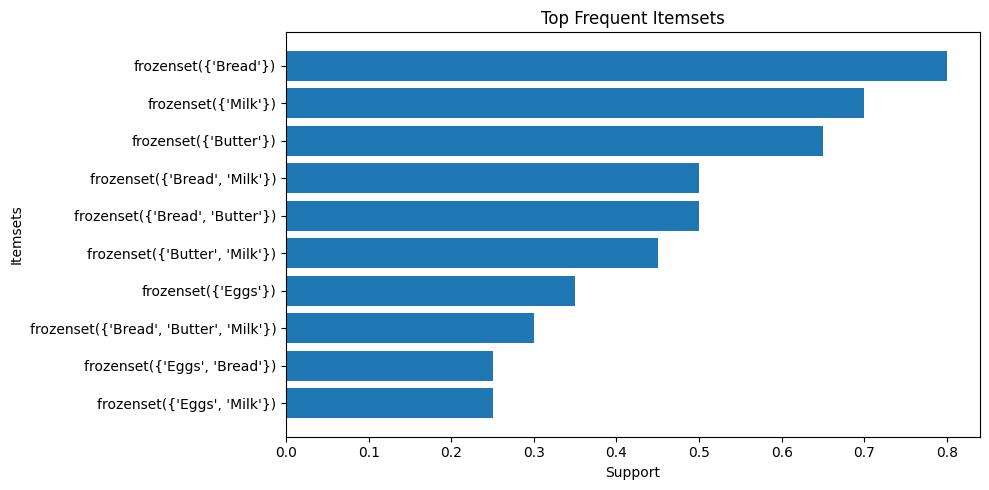

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

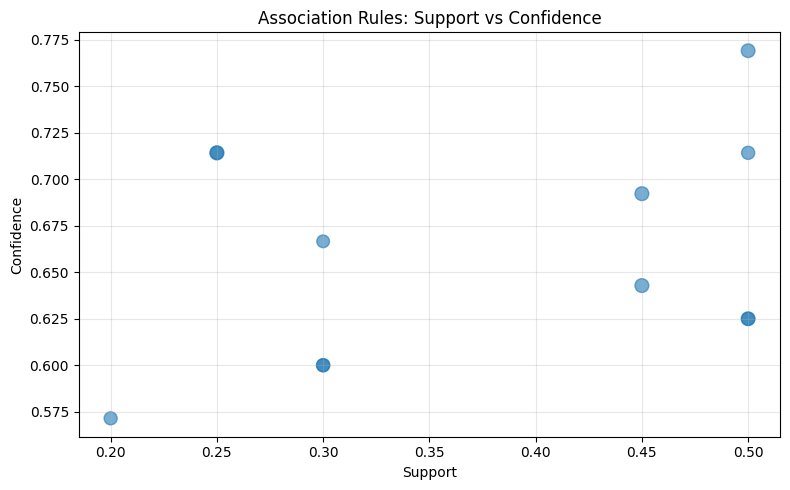


6. BEST ASSOCIATION RULE
Antecedent: Eggs
Consequent: Milk
Support: 0.250
Confidence: 71.43%
Lift: 1.020

7. ANALYSIS SUMMARY
Total transactions: 20
Unique products: 5
Frequent itemsets found: 11
Association rules generated: 12

INTERPRETATION OF METRICS
Support    : How frequently an itemset appears in transactions.
Confidence : Probability of buying the consequent given the antecedent.
Lift       : Strength of association compared with independent purchases.

Market Basket Analysis completed successfully!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [1]:
# MARKET BASKET ANALYSIS - PARTHIV ABHANI

import sys
import subprocess
import itertools
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Install required libraries automatically
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "mlxtend"
])

from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# 1. INBUILT DATASET
transactions = [
    ['Milk', 'Bread', 'Butter'],
    ['Bread', 'Butter'],
    ['Milk', 'Bread'],
    ['Milk', 'Bread', 'Butter', 'Eggs'],
    ['Bread', 'Eggs'],
    ['Milk', 'Butter'],
    ['Milk', 'Bread', 'Butter'],
    ['Bread', 'Butter', 'Eggs'],
    ['Milk', 'Bread', 'Eggs'],
    ['Milk', 'Bread', 'Butter'],
    ['Milk', 'Eggs'],
    ['Bread', 'Butter'],
    ['Milk', 'Bread', 'Butter', 'Eggs'],
    ['Bread', 'Milk'],
    ['Milk', 'Butter', 'Eggs'],
    ['Bread', 'Butter', 'Jam'],
    ['Bread', 'Jam'],
    ['Milk', 'Bread', 'Jam'],
    ['Milk', 'Butter'],
    ['Bread', 'Butter', 'Milk']
]

print("=" * 60)
print("MARKET BASKET ANALYSIS")
print("=" * 60)

print("\n1. ORIGINAL TRANSACTION DATASET")
for i, transaction in enumerate(transactions, 1):
    print(f"Transaction {i}: {', '.join(transaction)}")

print(f"\nTotal transactions: {len(transactions)}")

# 2. CONVERT TRANSACTIONS INTO ONE-HOT ENCODED DATAFRAME
encoder = TransactionEncoder()
encoded_array = encoder.fit(transactions).transform(transactions)

df = pd.DataFrame(
    encoded_array,
    columns=encoder.columns_
)

print("\n2. ONE-HOT ENCODED DATA")
print(df.astype(int).head(10).to_string())

# 3. FIND FREQUENT ITEMSETS USING APRIORI
frequent_itemsets = apriori(
    df,
    min_support=0.20,
    use_colnames=True
)

frequent_itemsets['itemsets'] = frequent_itemsets['itemsets'].apply(
    lambda x: ', '.join(sorted(list(x)))
)

print("\n3. FREQUENT ITEMSETS")
print(
    frequent_itemsets.sort_values(
        by='support', ascending=False
    ).to_string(index=False)
)

# Recalculate itemsets for association rule generation
frequent_itemsets = apriori(
    df,
    min_support=0.20,
    use_colnames=True
)

# 4. GENERATE ASSOCIATION RULES
rules = association_rules(
    frequent_itemsets,
    metric='confidence',
    min_threshold=0.50
)

if not rules.empty:
    rules['antecedents'] = rules['antecedents'].apply(
        lambda x: ', '.join(sorted(list(x)))
    )
    rules['consequents'] = rules['consequents'].apply(
        lambda x: ', '.join(sorted(list(x)))
    )

    rules = rules.sort_values(
        by='lift', ascending=False
    )

    print("\n4. ASSOCIATION RULES")
    print(
        rules[
            ['antecedents', 'consequents',
             'support', 'confidence', 'lift']
        ].round(3).to_string(index=False)
    )

    # 5. INTERPRETATION OF RULES
    print("\n5. BUSINESS INTERPRETATION")
    for _, rule in rules.head(10).iterrows():
        print(
            f"If a customer buys [{rule['antecedents']}], "
            f"they may also buy [{rule['consequents']}]. "
            f"Confidence: {rule['confidence']:.2%}, "
            f"Lift: {rule['lift']:.2f}"
        )

    # 6. VISUALIZATION: TOP FREQUENT ITEMSETS
    top_items = frequent_itemsets.sort_values(
        by='support', ascending=False
    ).head(10).copy()

    top_items['itemsets'] = top_items['itemsets'].astype(str)

    plt.figure(figsize=(10, 5))
    plt.barh(
        top_items['itemsets'],
        top_items['support']
    )
    plt.xlabel('Support')
    plt.ylabel('Itemsets')
    plt.title('Top Frequent Itemsets')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

    # 7. VISUALIZATION: ASSOCIATION RULES
    plt.figure(figsize=(8, 5))
    plt.scatter(
        rules['support'],
        rules['confidence'],
        s=rules['lift'] * 100,
        alpha=0.6
    )
    plt.xlabel('Support')
    plt.ylabel('Confidence')
    plt.title('Association Rules: Support vs Confidence')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # 8. BEST RULE
    best_rule = rules.iloc[0]
    print("\n6. BEST ASSOCIATION RULE")
    print(f"Antecedent: {best_rule['antecedents']}")
    print(f"Consequent: {best_rule['consequents']}")
    print(f"Support: {best_rule['support']:.3f}")
    print(f"Confidence: {best_rule['confidence']:.2%}")
    print(f"Lift: {best_rule['lift']:.3f}")

else:
    print("\nNo association rules found. Try lowering min_threshold.")

# 9. SUMMARY
print("\n7. ANALYSIS SUMMARY")
print(f"Total transactions: {len(transactions)}")
print(f"Unique products: {len(encoder.columns_)}")
print(f"Frequent itemsets found: {len(frequent_itemsets)}")
print(f"Association rules generated: {len(rules)}")

print("\nINTERPRETATION OF METRICS")
print("Support    : How frequently an itemset appears in transactions.")
print("Confidence : Probability of buying the consequent given the antecedent.")
print("Lift       : Strength of association compared with independent purchases.")
print("\nMarket Basket Analysis completed successfully!")